In [ ]:
# Cell 1: Install the only external helper needed for data download.
%pip -q install kagglehub

In [ ]:
# Cell 2: Imports and reproducibility settings
import os
import re
import json
import random
import unicodedata
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import kagglehub

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding, Conv1D, Bidirectional, LSTM, Dense, Dropout,
    SpatialDropout1D
)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from IPython.display import display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
print("Reproducibility seed:", SEED)

TensorFlow: 2.21.0
Reproducibility seed: 42


In [ ]:
# Cell 3: Download and load the Kaggle dataset
dataset_path = kagglehub.dataset_download(
    "zarajamshaid/language-identification-datasst"
)
print("Dataset path:", dataset_path)

csv_files = []
for root, _, files in os.walk(dataset_path):
    for filename in files:
        if filename.lower().endswith(".csv"):
            csv_files.append(os.path.join(root, filename))

if not csv_files:
    raise FileNotFoundError(
        f"No CSV files were found under dataset path: {dataset_path}"
    )

print("CSV files found:")
for file_path in csv_files:
    print(" -", file_path)

# The original dataset is expected to contain one main CSV.
# If multiple CSV files exist, select the file named dataset.csv when available.
preferred = [p for p in csv_files if os.path.basename(p).lower() == "dataset.csv"]
csv_path = preferred[0] if preferred else csv_files[0]

df_original = pd.read_csv(csv_path).copy(deep=True)
print("\nLoaded:", csv_path)
print("Original shape:", df_original.shape)
print("Columns:", df_original.columns.tolist())
display(df_original.head())

Using Colab cache for faster access to the 'language-identification-datasst' dataset.
Dataset path: /kaggle/input/language-identification-datasst
CSV files found:
 - /kaggle/input/language-identification-datasst/dataset.csv

Loaded: /kaggle/input/language-identification-datasst/dataset.csv
Original shape: (22000, 2)
Columns: ['Text', 'language']


,Text,language
0,klement gottwaldi surnukeha palsameeriti ning ...,Estonian
1,sebes joseph pereira thomas på eng the jesuit...,Swedish
2,ถนนเจริญกรุง อักษรโรมัน thanon charoen krung เ...,Thai
3,விசாகப்பட்டினம் தமிழ்ச்சங்கத்தை இந்துப் பத்திர...,Tamil
4,de spons behoort tot het geslacht haliclona en...,Dutch


In [ ]:
# Cell 4: Clean text conservatively and audit likely label issues
# The original DataFrame is preserved in df_original.
column_lookup = {str(c).strip().casefold(): c for c in df_original.columns}

TEXT_COL = next(
    (column_lookup[k] for k in ("text", "sentence", "text_data", "content") if k in column_lookup),
    None
)
LABEL_COL = next(
    (column_lookup[k] for k in ("language", "lang", "label", "language_name") if k in column_lookup),
    None
)

if TEXT_COL is None or LABEL_COL is None:
    raise ValueError(
        "Could not identify text/language columns. "
        f"Found columns: {df_original.columns.tolist()}"
    )

print("Text column:", TEXT_COL)
print("Label column:", LABEL_COL)
print("\nOriginal missing values:")
print(df_original[[TEXT_COL, LABEL_COL]].isna().sum())

# Unicode NFC normalisation helps keep equivalent characters consistent.
def normalize_text(value):
    value = unicodedata.normalize("NFC", str(value))
    value = value.lower().strip()
    value = re.sub(r"\s+", " ", value)
    return value

work = df_original[[TEXT_COL, LABEL_COL]].copy()
work["_source_row"] = df_original.index
work = work.dropna(subset=[TEXT_COL, LABEL_COL]).copy()
work[TEXT_COL] = work[TEXT_COL].map(normalize_text)
work[LABEL_COL] = work[LABEL_COL].astype(str).str.strip()
work = work[(work[TEXT_COL] != "") & (work[LABEL_COL] != "")].copy()

# A repeated normalized text with conflicting labels is ambiguous.
label_counts_per_text = work.groupby(TEXT_COL)[LABEL_COL].nunique()
conflicting_texts = set(label_counts_per_text[label_counts_per_text > 1].index)

# Writing-system checks flag only examples with no character from their expected
# script and at least 20 Unicode letters. This does not detect mistakes between
# languages sharing a script (e.g., English/French or Arabic/Persian/Urdu).
SCRIPT_PATTERNS = {
    "Arabic": r"[\u0600-\u06FF\u0750-\u077F\u08A0-\u08FF]",
    "Chinese": r"[\u3400-\u4DBF\u4E00-\u9FFF]",
    "Hindi": r"[\u0900-\u097F]",
    "Japanese": r"[\u3040-\u30FF\u3400-\u4DBF\u4E00-\u9FFF]",
    "Korean": r"[\u1100-\u11FF\u3130-\u318F\uAC00-\uD7AF]",
    "Persian": r"[\u0600-\u06FF\u0750-\u077F\u08A0-\u08FF]",
    "Pushto": r"[\u0600-\u06FF\u0750-\u077F\u08A0-\u08FF]",
    "Russian": r"[\u0400-\u04FF]",
    "Tamil": r"[\u0B80-\u0BFF]",
    "Thai": r"[\u0E00-\u0E7F]",
    "Urdu": r"[\u0600-\u06FF\u0750-\u077F\u08A0-\u08FF]",
}
script_patterns_cf = {k.casefold(): re.compile(v) for k, v in SCRIPT_PATTERNS.items()}

def unicode_letter_count(text):
    return sum(unicodedata.category(ch).startswith("L") for ch in text)

script_mismatch_indices = []
for idx, row in work.iterrows():
    pattern = script_patterns_cf.get(str(row[LABEL_COL]).casefold())
    text = row[TEXT_COL]
    if pattern is None:
        continue
    if unicode_letter_count(text) >= 20 and not pattern.search(text):
        script_mismatch_indices.append(idx)

flag_reasons = defaultdict(list)
for idx, row in work.iterrows():
    if row[TEXT_COL] in conflicting_texts:
        flag_reasons[idx].append("Same normalized text appears with conflicting language labels")
for idx in script_mismatch_indices:
    flag_reasons[idx].append("No expected writing-system character in a long text; review label")

flagged_indices = set(flag_reasons.keys())
df_audit_flags = work.loc[work.index.isin(flagged_indices), [TEXT_COL, LABEL_COL, "_source_row"]].copy()
df_audit_flags["Audit_Reason"] = [
    "; ".join(flag_reasons[idx]) for idx in df_audit_flags.index
]

# Conservative default: quarantine flagged rows for review, don't auto-relabel.
# Set this to False if you want to retain all flagged rows for comparison.
QUARANTINE_FLAGGED_ROWS = True

if QUARANTINE_FLAGGED_ROWS:
    df_cleaned_candidate = work.loc[~work.index.isin(flagged_indices)].copy()
else:
    df_cleaned_candidate = work.copy()

rows_before_dedupe = len(df_cleaned_candidate)
df_cleaned_candidate = df_cleaned_candidate.drop_duplicates(
    subset=[TEXT_COL, LABEL_COL], keep="first"
).copy()
duplicate_pairs_removed = rows_before_dedupe - len(df_cleaned_candidate)
df_cleaned_candidate = df_cleaned_candidate.drop(columns=["_source_row"]).reset_index(drop=True)

# Save audit evidence separately. Original data remains unchanged in df_original.
audit_path = "/content/language_identification_audit_flags.csv"
df_audit_flags.to_csv(audit_path, index=False)

print("\n=== Data audit summary ===")
print("Original rows:", len(df_original))
print("Rows with conflicting duplicate labels:", sum(
    work[TEXT_COL].isin(conflicting_texts)
))
print("Rows flagged for writing-system mismatch:", len(script_mismatch_indices))
print("Unique flagged rows:", len(flagged_indices))
print("Flagged rows quarantined:", len(flagged_indices) if QUARANTINE_FLAGGED_ROWS else 0)
print("Repeated text-label pairs removed:", duplicate_pairs_removed)
print("Rows retained for modelling:", len(df_cleaned_candidate))
print("Audit CSV saved to:", audit_path)
print("\nClass counts after audit:")
display(df_cleaned_candidate[LABEL_COL].value_counts().rename("samples").to_frame())

print("\nReview examples (first 20 flagged rows):")
display(df_audit_flags.head(20))

Text column: Text
Label column: language

Original missing values:
Text        0
language    0
dtype: int64

=== Data audit summary ===
Original rows: 22000
Rows with conflicting duplicate labels: 0
Rows flagged for writing-system mismatch: 110
Unique flagged rows: 110
Flagged rows quarantined: 110
Repeated text-label pairs removed: 140
Rows retained for modelling: 21749
Audit CSV saved to: /content/language_identification_audit_flags.csv

Class counts after audit:


,samples
language,
English,1000
Turkish,1000
Romanian,1000
Estonian,999
Persian,998
Portugese,997
Arabic,996
Spanish,996
Russian,995



Review examples (first 20 flagged rows):


,Text,language,_source_row,Audit_Reason
66,titsingh i illustrations of japan consisting o...,Thai,66,No expected writing-system character in a long...
83,^ hwang sw et al direct activation of capsaici...,Korean,83,No expected writing-system character in a long...
246,his book the year china discovered the world i...,Japanese,246,No expected writing-system character in a long...
355,military strength is a term that describes a q...,Pushto,355,No expected writing-system character in a long...
506,the physics of antisthenes contained a theory ...,Pushto,506,No expected writing-system character in a long...
753,"grand cross of the iron cross for ""the victori...",Thai,753,No expected writing-system character in a long...
1034,in the us established a central intelligence a...,Hindi,1034,No expected writing-system character in a long...
1177,pencilline neomycine streptomycine erythromyci...,Pushto,1177,No expected writing-system character in a long...
1215,jack s blocker et al eds alcohol and temperanc...,Pushto,1215,No expected writing-system character in a long...
1429,mathematical economic is an approach analysis ...,Pushto,1429,No expected writing-system character in a long...


In [ ]:
# Cell 5: Create reproducible, stratified train/validation/test splits
# The test set is held out before any training-only augmentation.
X_all = df_cleaned_candidate[TEXT_COL].astype(str).to_numpy()
labels_all = df_cleaned_candidate[LABEL_COL].astype(str).to_numpy()

label_encoder = LabelEncoder()
y_all = label_encoder.fit_transform(labels_all)
NUM_CLASSES = len(label_encoder.classes_)

if NUM_CLASSES != 22:
    raise ValueError(
        f"Expected the dataset's 22 language classes, but found {NUM_CLASSES}: "
        f"{list(label_encoder.classes_)}. Review the audit/quarantine settings."
    )

class_counts = pd.Series(labels_all).value_counts()
if (class_counts < 3).any():
    raise ValueError(
        "At least one class has fewer than 3 examples; stratified splitting "
        f"may not be reliable. Counts: {class_counts[class_counts < 3].to_dict()}"
    )

X_train_raw, X_test, y_train_raw, y_test = train_test_split(
    X_all,
    y_all,
    test_size=0.20,
    random_state=SEED,
    stratify=y_all,
)

X_train_raw, X_val, y_train_raw, y_val = train_test_split(
    X_train_raw,
    y_train_raw,
    test_size=0.10,
    random_state=SEED,
    stratify=y_train_raw,
)

# Because exact normalized texts were deduplicated before splitting, exact
# duplicate strings should not leak across splits.
assert not (set(X_train_raw) & set(X_val))
assert not (set(X_train_raw) & set(X_test))
assert not (set(X_val) & set(X_test))

print("Supported classes:", NUM_CLASSES)
print("Train source examples:", len(X_train_raw))
print("Validation examples:", len(X_val))
print("Held-out test examples:", len(X_test))
print("\nClass order used by the model:")
for index, language in enumerate(label_encoder.classes_):
    print(f"{index:2d}: {language}")

Supported classes: 22
Train source examples: 15659
Validation examples: 1740
Held-out test examples: 4350

Class order used by the model:
 0: Arabic
 1: Chinese
 2: Dutch
 3: English
 4: Estonian
 5: French
 6: Hindi
 7: Indonesian
 8: Japanese
 9: Korean
10: Latin
11: Persian
12: Portugese
13: Pushto
14: Romanian
15: Russian
16: Spanish
17: Swedish
18: Tamil
19: Thai
20: Turkish
21: Urdu


In [ ]:
# Cell 6: Generate short fragments from TRAINING DATA ONLY
# Unicode category 'L' includes letters from Tamil, Arabic, Cyrillic, Thai,
# CJK, Latin, and other writing systems. No ASCII-only filter is used.

MAX_FRAGMENT_CHARS = 100
MIN_FRAGMENT_CHARS = 20
FRAGMENTS_PER_SOURCE = 2
rng = np.random.default_rng(SEED)

def is_valid_fragment(fragment):
    fragment = fragment.strip()
    if len(fragment) < MIN_FRAGMENT_CHARS:
        return False

    letters = [
        ch for ch in fragment
        if unicodedata.category(ch).startswith("L")
    ]
    if len(letters) < 12:
        return False

    letter_ratio = len(letters) / max(len(fragment), 1)
    if letter_ratio < 0.45:
        return False

    # Avoid chunks consisting almost entirely of one repeated letter.
    if len(set(ch.casefold() for ch in letters)) < 4:
        return False

    return True

def make_short_fragment(text, rng):
    text = normalize_text(text)
    if len(text) <= MIN_FRAGMENT_CHARS:
        return None

    # Prefer sentence-like segments when punctuation is available.
    segments = re.split(r"(?<=[.!?。！？؟۔])\s+|[\r\n]+", text)
    candidates = [
        segment.strip()
        for segment in segments
        if len(segment.strip()) >= MIN_FRAGMENT_CHARS
    ]
    base = str(rng.choice(candidates)) if candidates else text

    # If a chosen segment is too long, take a reproducible random character span.
    upper = min(MAX_FRAGMENT_CHARS, len(base))
    if upper < MIN_FRAGMENT_CHARS:
        base = text
        upper = min(MAX_FRAGMENT_CHARS, len(base))
    if upper < MIN_FRAGMENT_CHARS:
        return None

    for _ in range(5):
        length = int(rng.integers(MIN_FRAGMENT_CHARS, upper + 1))
        max_start = len(base) - length
        start = int(rng.integers(0, max_start + 1)) if max_start > 0 else 0
        fragment = base[start:start + length].strip()

        # Prefer word boundaries for whitespace-separated scripts when available.
        if " " in fragment and len(fragment) > MIN_FRAGMENT_CHARS:
            fragment = fragment.strip(" ,;:-")
        if is_valid_fragment(fragment) and fragment != text:
            return fragment

    return None

fragment_texts = []
fragment_labels = []

for text, label in zip(X_train_raw, y_train_raw):
    for _ in range(FRAGMENTS_PER_SOURCE):
        fragment = make_short_fragment(text, rng)
        if fragment:
            fragment_texts.append(fragment)
            fragment_labels.append(int(label))

if not fragment_texts:
    raise RuntimeError(
        "No short fragments were generated. Inspect the dataset and fragment rules."
    )

# Combine original training examples with training-derived fragments, then shuffle.
X_train_augmented = np.concatenate([
    X_train_raw,
    np.asarray(fragment_texts, dtype=object)
])
y_train_augmented = np.concatenate([
    y_train_raw,
    np.asarray(fragment_labels, dtype=np.int64)
])

shuffle_indices = rng.permutation(len(X_train_augmented))
X_train_augmented = X_train_augmented[shuffle_indices]
y_train_augmented = y_train_augmented[shuffle_indices]

fragment_df = pd.DataFrame({
    "Text": fragment_texts,
    "Language": label_encoder.inverse_transform(np.asarray(fragment_labels, dtype=int))
})

print("Original training samples:", len(X_train_raw))
print("Generated short fragments:", len(fragment_texts))
print("Combined training samples:", len(X_train_augmented))
print("\nGenerated fragments per language:")
display(
    fragment_df["Language"]
    .value_counts()
    .reindex(label_encoder.classes_, fill_value=0)
    .rename("fragments")
    .to_frame()
)

print("\nRepresentative fragments (up to 2 per language):")
for language in label_encoder.classes_:
    examples = fragment_df.loc[fragment_df["Language"] == language, "Text"].head(2).tolist()
    print(f"\n{language}:")
    for example in examples:
        print(" -", example)

Original training samples: 15659
Generated short fragments: 31308
Combined training samples: 46967

Generated fragments per language:


,fragments
Language,
Arabic,1434
Chinese,1432
Dutch,1432
English,1440
Estonian,1438
French,1426
Hindi,1398
Indonesian,1404
Japanese,1426



Representative fragments (up to 2 per language):

Arabic:
 - اف المحلي ونال إعجاب من في المكتب بعد إتقا
 - نة القاهرة والتحق بالمدرسة الناصرية الابتدائية بالقاهرة وحصل منها على الشهادة الابتدائية ثم التحق عا

Chinese:
 - 型次矮星（sdb）克卜勒的類地行星。該行星系統亦另有一
 - 行星，克卜勒c，而這兩顆行星均相當接近母恆星。克卜勒b的軌道週期只有小時，從發現至今是公轉週期最短的系外行星。截至年，這顆行星是表面溫度最高的系外行星，其平均表面溫

Dutch:
 - super sentai en komen meestal voo
 - evechten deze zords zijn overgenomen van de mecha uit super sentai en k

English:
 - gerank algorithm and realized that it could be used to build a s
 - re of importance for a given web page brin and page deve

Estonian:
 - l keenia senatisse mbita valimisringkonnast ja aastal h
 - l keenia senatisse mbita v

French:
 - de documentation • biblioth
 - standard name identifier • bibliothèque nationale de france données • sys

Hindi:
 - म का प्रतिशत हिस्सा उगाया
 - जिसे देश में उगाया जाता है। अकेले कर्नाटक में इस किस्म

Indonesian:
 - bagian dari ordo araneae nama ilmiah dari spesies ini pertama kali diterb
 - a

In [ ]:
# Cell 7: Fit the character tokenizer on TRAINING DATA ONLY
MAX_LEN = 300

tokenizer = Tokenizer(
    char_level=True,
    lower=True,
    filters="",
    oov_token="<OOV>",
)
tokenizer.fit_on_texts(X_train_augmented)

X_train_seq = tokenizer.texts_to_sequences(X_train_augmented)
X_val_seq = tokenizer.texts_to_sequences(X_val)
X_test_seq = tokenizer.texts_to_sequences(X_test)

X_train_pad = pad_sequences(
    X_train_seq, maxlen=MAX_LEN, padding="post", truncating="post"
)
X_val_pad = pad_sequences(
    X_val_seq, maxlen=MAX_LEN, padding="post", truncating="post"
)
X_test_pad = pad_sequences(
    X_test_seq, maxlen=MAX_LEN, padding="post", truncating="post"
)

VOCAB_SIZE = len(tokenizer.word_index) + 1

print("Character vocabulary size:", VOCAB_SIZE)
print("MAX_LEN:", MAX_LEN)
print("Train tensor:", X_train_pad.shape, y_train_augmented.shape)
print("Validation tensor:", X_val_pad.shape, y_val.shape)
print("Held-out test tensor:", X_test_pad.shape, y_test.shape)

assert X_train_pad.shape[0] == len(y_train_augmented)
assert X_val_pad.shape[0] == len(y_val)
assert X_test_pad.shape[0] == len(y_test)

Character vocabulary size: 6661
MAX_LEN: 300
Train tensor: (46967, 300) (46967,)
Validation tensor: (1740, 300) (1740,)
Held-out test tensor: (4350, 300) (4350,)


In [ ]:
# Cell 8: Build and train the existing Conv1D + Bidirectional LSTM architecture
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)

model = Sequential([
    Embedding(input_dim=VOCAB_SIZE, output_dim=128, mask_zero=False),
    SpatialDropout1D(0.25),
    Conv1D(filters=128, kernel_size=5, activation="relu", padding="same"),
    Bidirectional(LSTM(128, return_sequences=False)),
    Dropout(0.4),
    Dense(64, activation="relu"),
    Dropout(0.3),
    Dense(NUM_CLASSES, activation="softmax"),
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True,
    verbose=1,
)
reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=1,
    min_lr=1e-5,
    verbose=1,
)

model.summary()

history = model.fit(
    X_train_pad,
    y_train_augmented,
    validation_data=(X_val_pad, y_val),
    epochs=10,
    batch_size=64,
    callbacks=[early_stopping, reduce_lr],
    verbose=1,
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ ?                      │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
734/734 ━━━━━━━━━━━━━━━━━━━━ 33s 34ms/step - accuracy: 0.4965 - loss: 1.3884 - val_accuracy: 0.7655 - val_loss: 0.6019 - learning_rate: 0.0010
Epoch 2/10
734/734 ━━━━━━━━━━━━━━━━━━━━ 25s 34ms/step - accuracy: 0.7685 - loss: 0.6508 - val_accuracy: 0.8695 - val_loss: 0.3348 - learning_rate: 0.0010
Epoch 3/10
734/734 ━━━━━━━━━━━━━━━━━━━━ 25s 34ms/step - accuracy: 0.8651 - loss: 0.4199 - val_accuracy: 0.9661 - val_loss: 0.1376 - learning_rate: 0.0010
Epoch 4/10
734/734 ━━━━━━━━━━━━━━━━━━━━ 25s 35ms/step - accuracy: 0.9157 - loss: 0.3065 - val_accuracy: 0.9851 - val_loss: 0.0682 - learning_rate: 0.0010
Epoch 5/10
734/734 ━━━━━━━━━━━━━━━━━━━━ 26s 35ms/step - accuracy: 0.9367 - loss: 0.2455 - val_accuracy: 0.9879 - val_loss: 0.0564 - learning_rate: 0.0010
Epoch 6/10
734/734 ━━━━━━━━━━━━━━━━━━━━ 26s 36ms/step - accuracy: 0.9490 - loss: 0.2014 - val_accuracy: 0.9897 - val_loss: 0.0531 - learning_rate: 0.0010
Epoch 7/10
734/734 ━━━━━━━━━━━━━━━━━━━━ 26s 35ms/step - accuracy: 0.9547 - l

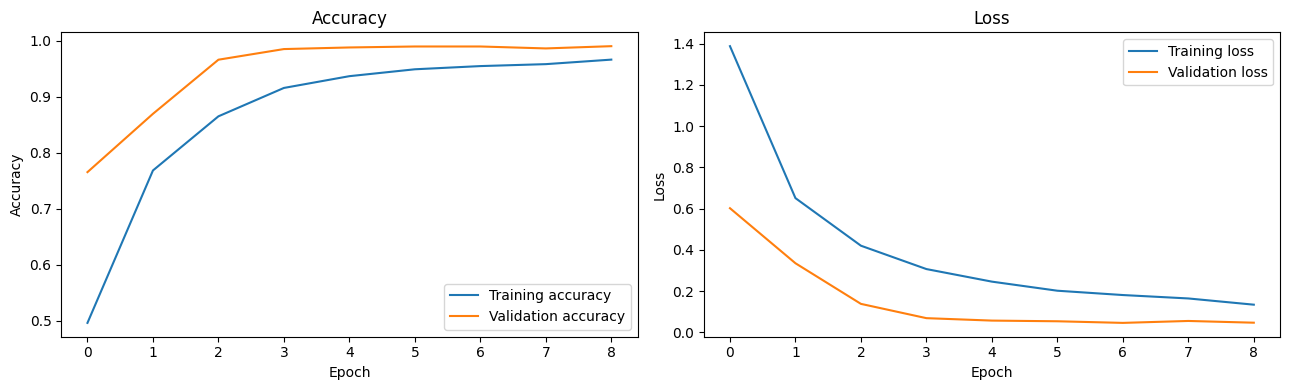

In [ ]:
# Cell 9: Plot training curves
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(history.history["accuracy"], label="Training accuracy")
axes[0].plot(history.history["val_accuracy"], label="Validation accuracy")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(history.history["loss"], label="Training loss")
axes[1].plot(history.history["val_loss"], label="Validation loss")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.show()

In [ ]:
# Cell 10: Final evaluation on the untouched held-out test set
# Use this test set once for final reporting, not for iterative tuning.
test_loss, test_accuracy = model.evaluate(X_test_pad, y_test, verbose=0)
y_test_prob = model.predict(X_test_pad, verbose=0)
y_test_pred = np.argmax(y_test_prob, axis=1)

metrics_summary = {
    "Test loss": float(test_loss),
    "Accuracy": accuracy_score(y_test, y_test_pred),
    "Macro precision": precision_score(y_test, y_test_pred, average="macro", zero_division=0),
    "Macro recall": recall_score(y_test, y_test_pred, average="macro", zero_division=0),
    "Macro F1": f1_score(y_test, y_test_pred, average="macro", zero_division=0),
    "Weighted precision": precision_score(y_test, y_test_pred, average="weighted", zero_division=0),
    "Weighted recall": recall_score(y_test, y_test_pred, average="weighted", zero_division=0),
    "Weighted F1": f1_score(y_test, y_test_pred, average="weighted", zero_division=0),
}
print("=== Final held-out test metrics ===")
for name, value in metrics_summary.items():
    print(f"{name:20s}: {value:.4f}" if name == "Test loss" else f"{name:20s}: {value * 100:.2f}%")

print("\n=== Per-language report ===")
print(classification_report(
    y_test,
    y_test_pred,
    labels=np.arange(NUM_CLASSES),
    target_names=label_encoder.classes_,
    zero_division=0,
))

report_dict = classification_report(
    y_test,
    y_test_pred,
    labels=np.arange(NUM_CLASSES),
    target_names=label_encoder.classes_,
    zero_division=0,
    output_dict=True,
)
per_language_report = pd.DataFrame(report_dict).T
display(per_language_report)

=== Final held-out test metrics ===
Test loss           : 0.0738
Accuracy            : 98.30%
Macro precision     : 98.40%
Macro recall        : 98.28%
Macro F1            : 98.30%
Weighted precision  : 98.39%
Weighted recall     : 98.30%
Weighted F1         : 98.30%

=== Per-language report ===
              precision    recall  f1-score   support

      Arabic       0.99      1.00      1.00       199
     Chinese       0.99      0.99      0.99       199
       Dutch       0.98      0.99      0.98       199
     English       0.86      0.98      0.92       200
    Estonian       0.98      0.98      0.98       200
      French       0.95      1.00      0.98       198
       Hindi       1.00      0.99      1.00       195
  Indonesian       0.99      0.95      0.97       195
    Japanese       1.00      0.99      1.00       198
      Korean       1.00      1.00      1.00       198
       Latin       0.99      0.86      0.92       191
     Persian       0.99      1.00      1.00       200


,precision,recall,f1-score,support
Arabic,0.995000,1.000000,0.997494,199.000000
Chinese,0.994949,0.989950,0.992443,199.000000
Dutch,0.980100,0.989950,0.985000,199.000000
English,0.863436,0.980000,0.918033,200.000000
Estonian,0.975124,0.980000,0.977556,200.000000
French,0.951923,1.000000,0.975369,198.000000
Hindi,1.000000,0.994872,0.997429,195.000000
Indonesian,0.994624,0.948718,0.971129,195.000000
Japanese,1.000000,0.994949,0.997468,198.000000
Korean,1.000000,1.000000,1.000000,198.000000


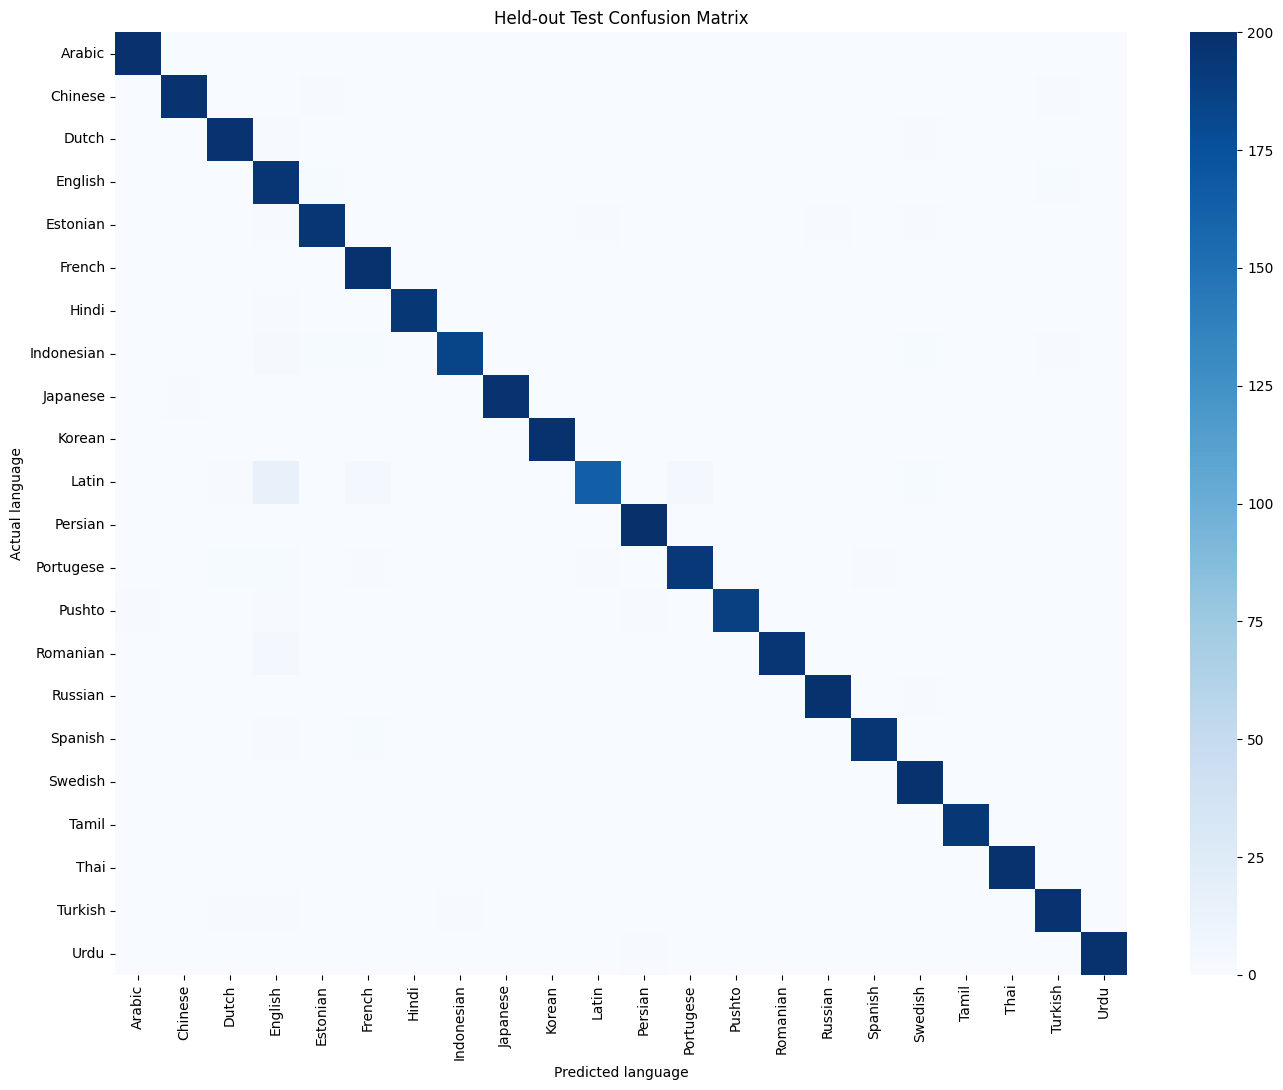

=== Held-out accuracy by original test-text length ===


,Samples,Accuracy,Accuracy (%)
length_group,,,
1–49 chars,0,NaN,NaN
50–99 chars,0,NaN,NaN
100–199 chars,1279,0.959343,95.93
200+ chars,3071,0.992836,99.28



Most frequent error pairs:


,actual,predicted,Count
0,Latin,English,15
1,Latin,French,5
2,Romanian,English,5
3,Latin,Portugese,4
4,Indonesian,English,3
5,English,Estonian,2
6,Portugese,English,2
7,Spanish,French,2
8,Portugese,Dutch,2
9,Latin,Swedish,2


In [ ]:
# Cell 11: Confusion matrix and accuracy by text length
cm = confusion_matrix(y_test, y_test_pred, labels=np.arange(NUM_CLASSES))

plt.figure(figsize=(14, 11))
sns.heatmap(
    cm,
    cmap="Blues",
    annot=False,
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_,
)
plt.title("Held-out Test Confusion Matrix")
plt.xlabel("Predicted language")
plt.ylabel("Actual language")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

test_diagnostics = pd.DataFrame({
    "text": X_test,
    "actual": label_encoder.inverse_transform(y_test),
    "predicted": label_encoder.inverse_transform(y_test_pred),
    "correct": y_test == y_test_pred,
})
test_diagnostics["characters"] = test_diagnostics["text"].str.len()
test_diagnostics["length_group"] = pd.cut(
    test_diagnostics["characters"],
    bins=[0, 49, 99, 199, float("inf")],
    labels=["1–49 chars", "50–99 chars", "100–199 chars", "200+ chars"],
    include_lowest=True,
)

length_report = test_diagnostics.groupby("length_group", observed=False).agg(
    Samples=("correct", "size"),
    Accuracy=("correct", "mean"),
)
length_report["Accuracy (%)"] = (length_report["Accuracy"] * 100).round(2)
print("=== Held-out accuracy by original test-text length ===")
display(length_report)

print("\nMost frequent error pairs:")
error_pairs = (
    test_diagnostics.loc[~test_diagnostics["correct"]]
    .groupby(["actual", "predicted"])
    .size()
    .sort_values(ascending=False)
    .head(15)
    .reset_index(name="Count")
)
display(error_pairs)

In [ ]:
# Cell 12: 10 curated short-text examples per supported language
short_eval_data = {
    "Arabic": [
        "مرحبا بك في العالم الجديد.", "اللغة العربية لغة جميلة جدا.", "الطقس اليوم حار ولطيف.",
        "أين يمكنني العثور على كتاب؟", "أنا أحب القراءة والكتابة.", "هذا النص قصير وبسيط.",
        "البيت كبير والحديقة واسعة.", "شكرا جزيلا على مساعدتك.", "متى ستبدأ المحاضرة غدا؟",
        "نهر النيل نهر طويل ومشهور."
    ],
    "Chinese": [
        "你好，世界。", "中文非常有趣。", "今天天气很好。", "我想读这本书。", "这是一段短文本。",
        "我喜欢学习新语言。", "很高兴认识你。", "你叫什么名字？", "这支笔是红色的。", "我们一起去吃饭吧。"
    ],
    "Dutch": [
        "Hallo wereld.", "Dit is een korte zin.", "De zon schijnt vandaag.", "Ik leer Nederlands.",
        "Waar is de bibliotheek?", "Wat is je naam?", "Het is koud buiten.", "Veel succes met je werk.",
        "Ik hou van boeken.", "De trein komt op tijd."
    ],
    "English": [
        "Hello world.", "The sun is shining today.", "Short text is easy to read.",
        "Where is the nearest bank?", "I love coding in Python.", "What a beautiful morning.",
        "Please keep this quiet.", "We need to move quickly.", "The cat slept on the rug.",
        "Learning is always fun."
    ],
    "Estonian": [
        "Tere maailm.", "See on lühike lause.", "Täna paistab päike.", "Ma õpin eesti keelt.",
        "Kus asub raamatukogu?", "Mis su nimi on?", "Väljas on külm.", "Palju õnne sünnipäevaks.",
        "Mulle meeldivad raamatud.", "Rong saabub õigel ajal."
    ],
    "French": [
        "Bonjour le monde.", "Ceci est une phrase courte.", "Le soleil brille aujourd'hui.",
        "J'apprends le français.", "Où est la bibliothèque ?", "Comment vous appelez-vous ?",
        "Il fait froid dehors.", "Bonne chance avec ton travail.", "J'adore lire des livres.",
        "Le train arrive à l'heure."
    ],
    "Hindi": [
        "नमस्ते दुनिया।", "यह एक छोटा वाक्य है।", "आज धूप खिली हुई है।", "मैं हिंदी सीख रहा हूँ।",
        "पुस्तकालय कहाँ है?", "आपका नाम क्या है?", "बाहर ठंड है।", "जन्मदिन की शुभकामनाएँ।",
        "मुझे किताबें पसंद हैं।", "ट्रेन समय पर आ रही है।"
    ],
    "Indonesian": [
        "Halo dunia.", "Ini adalah kalimat pendek.", "Matahari bersinar hari ini.",
        "Saya belajar bahasa Indonesia.", "Di mana perpustakaannya?", "Siapa nama Anda?",
        "Udara di luar dingin.", "Semoga sukses dengan pekerjaanmu.", "Saya suka membaca buku.",
        "Kereta datang tepat waktu."
    ],
    "Japanese": [
        "こんにちは、世界。", "これは短い文章です。", "今日は晴れています。", "私は日本語を学びます。",
        "図書館はどこですか？", "お名前は何ですか？", "外は寒いです。", "誕生日おめでとう。",
        "私は本が好きです。", "電車は定刻に到着します。"
    ],
    "Korean": [
        "안녕하세요, 세계.", "이것은 짧은 문장입니다.", "오늘 날씨가 맑습니다.",
        "나는 한국어를 배웁니다.", "도서관은 어디에 있습니까?", "이름이 무엇입니까?",
        "밖은 춥습니다.", "생일 축하합니다.", "나는 책을 좋아합니다.", "기차가 제시간에 도착합니다."
    ],
    "Latin": [
        "Salve munde.", "Haec est sententia brevis.", "Sol hodie lucet.", "Linguam Latinam disco.",
        "Ubi est bibliotheca?", "Quod nomen tibi est?", "Frigidum est foris.", "Felix dies natalis.",
        "Libros legere amo.", "Tramen ad tempus venit."
    ],
    "Persian": [
        "سلام دنیا.", "این یک جمله کوتاه است.", "امروز هوا آفتابی است.", "من فارسی یاد می‌گیرم.",
        "کتابخانه کجاست؟", "نام شما چیست؟", "بیرون سرد است.", "تولدت مبارک.", "من عاشق خواندن کتابم.",
        "قطار به موقع می‌رسد."
    ],
    "Portugese": [
        "Olá mundo.", "Esta é uma frase curta.", "O sol está brilhando hoje.",
        "Estou aprendendo português.", "Onde fica a biblioteca?", "Qual é o seu nome?",
        "Está frio lá fora.", "Boa sorte com seu trabalho.", "Eu amo ler livros.",
        "O trem chega no horário."
    ],
    "Pushto": [
        "سلام نړۍ.", "دا یوه لنډه جمله ده.", "نن لمر ځلیږي.", "زه پښتو زده کوم.",
        "کتابتون چیرته دی؟", "ستاسو نوم څه دی؟", "بهر یخني ده.", "د زوکړې ورځ دې مبارک شه.",
        "زه کتابونه خوښوم.", "اورګاډی پر وخت راځي."
    ],
    "Romanian": [
        "Salut lume.", "Aceasta este o frază scurtă.", "Soarele strălucește astăzi.",
        "Învăț limba română.", "Unde este biblioteca?", "Cum te numești?",
        "Este frig afară.", "Mult succes cu munca ta.", "Îmi place să citesc cărți.",
        "Trenul sosește la timp."
    ],
    "Russian": [
        "Привет, мир.", "Это короткое предложение.", "Сегодня светит солнце.", "Я учу русский язык.",
        "Где библиотека?", "Как вас зовут?", "На улице холодно.", "С днём рождения.",
        "Я люблю читать книги.", "Поезд прибывает вовремя."
    ],
    "Spanish": [
        "Hola mundo.", "Esta es una frase corta.", "El sol brilla hoy.", "Estoy aprendiendo español.",
        "¿Dónde está la biblioteca?", "¿Cómo te llamas?", "Hace frío afuera.",
        "Buena suerte con tu trabajo.", "Me encanta leer libros.", "El tren llega a tiempo."
    ],
    "Swedish": [
        "Hej världen.", "Det här är en kort mening.", "Solen skiner idag.", "Jag lär mig svenska.",
        "Var ligger biblioteket?", "Vad heter du?", "Det är kallt ute.", "Grattis på födelsedagen.",
        "Jag älskar att läsa böcker.", "Tåget anländer i tid."
    ],
    "Tamil": [
        "வணக்கம் உலகமே.", "இது ஒரு குறுகிய வாக்கியம்.", "இன்று சூரியன் பிரகாசிக்கிறது.",
        "நான் தமிழ் கற்கிறேன்.", "நூலகம் எங்கே உள்ளது?", "உன் பெயர் என்ன?",
        "வெளியே குளிராக இருக்கிறது.", "இனிய பிறந்தநாள் வாழ்த்துகள்.", "எனக்கு புத்தகங்கள் பிடிக்கும்.",
        "இரயில் சரியான நேரத்தில் வரும்."
    ],
    "Thai": [
        "สวัสดีโลก", "นี่คือประโยคสั้นๆ", "วันนี้พระอาทิตย์ส่องแสง", "ฉันกำลังเรียนภาษาไทย",
        "ห้องสมุดอยู่ที่ไหน", "คุณชื่ออะไร", "ข้างนอกหนาวมาก", "สุขสันต์วันเกิด",
        "ฉันชอบอ่านหนังสือ", "รถไฟมาตรงเวลา"
    ],
    "Turkish": [
        "Merhaba dünya.", "Bu kısa bir cümledir.", "Bugün güneş parlıyor.",
        "Türkçe öğreniyorum.", "Kütüphane nerede?", "Adınız nedir?", "Dışarısı soğuk.",
        "Doğum günün kutlu olsun.", "Kitap okumayı severim.", "Tren zamanında geliyor."
    ],
    "Urdu": [
        "ہیلو دنیا۔", "یہ ایک مختصر جملہ ہے۔", "آج سورج چمک رہا ہے۔", "میں اردو سیکھ رہا ہوں۔",
        "لائبریری کہاں ہے؟", "آپ کا نام کیا ہے؟", "باہر سردی ہے۔", "سالگرہ مبارک ہو۔",
        "مجھے کتابیں پڑھنا پسند ہیں۔", "ٹرین وقت پر آتی ہے۔"
    ],
}

assert set(short_eval_data) == set(label_encoder.classes_), (
    "Short-text suite language labels must match the model's language classes. "
    f"Missing: {set(label_encoder.classes_) - set(short_eval_data)}, "
    f"Extra: {set(short_eval_data) - set(label_encoder.classes_)}"
)
assert all(len(sentences) == 10 for sentences in short_eval_data.values())

short_texts = []
short_expected = []
for lang, sentences in short_eval_data.items():
    for sentence in sentences:
        short_texts.append(sentence)
        short_expected.append(lang)

print("Short-text smoke-test examples:", len(short_texts))
print("Minimum/maximum character lengths:", min(map(len, short_texts)), "/", max(map(len, short_texts)))

Short-text smoke-test examples: 220
Minimum/maximum character lengths: 6 / 33


In [ ]:
# Cell 13: Evaluate the short-text smoke test with the latest trained model
short_seq = tokenizer.texts_to_sequences([normalize_text(t) for t in short_texts])
short_pad = pad_sequences(
    short_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post",
)
short_prob = model.predict(short_pad, verbose=0)
short_pred_ids = np.argmax(short_prob, axis=1)
short_predicted = label_encoder.inverse_transform(short_pred_ids)
short_confidence = np.max(short_prob, axis=1) * 100

short_results = pd.DataFrame({
    "Input Text": short_texts,
    "Expected Language": short_expected,
    "Predicted Language": short_predicted,
    "Confidence (%)": np.round(short_confidence, 2),
})
short_results["Correct"] = short_results["Expected Language"] == short_results["Predicted Language"]

short_suite_accuracy = accuracy_score(
    label_encoder.transform(short_expected),
    short_pred_ids,
)
print(f"Short-text smoke-test accuracy: {short_suite_accuracy * 100:.2f}%")
print(f"Correct: {int(short_results['Correct'].sum())}/{len(short_results)}")

print("\nPer-language short-text results:")
short_by_language = (
    short_results.groupby("Expected Language")
    .agg(Samples=("Correct", "size"), Accuracy=("Correct", "mean"))
)
short_by_language["Accuracy (%)"] = (short_by_language["Accuracy"] * 100).round(2)
display(short_by_language)

print("\nIncorrect short-text predictions:")
display(short_results.loc[~short_results["Correct"]])

print("\nAll results:")
display(short_results)

Short-text smoke-test accuracy: 89.55%
Correct: 197/220

Per-language short-text results:


,Samples,Accuracy,Accuracy (%)
Expected Language,,,
Arabic,10,1.0,100.0
Chinese,10,0.9,90.0
Dutch,10,0.9,90.0
English,10,0.9,90.0
Estonian,10,0.6,60.0
French,10,0.9,90.0
Hindi,10,1.0,100.0
Indonesian,10,0.9,90.0
Japanese,10,1.0,100.0



Incorrect short-text predictions:


,Input Text,Expected Language,Predicted Language,Confidence (%),Correct
16,很高兴认识你。,Chinese,Persian,38.500000,False
23,Ik leer Nederlands.,Dutch,Swedish,33.080002,False
35,What a beautiful morning.,English,Romanian,47.910000,False
40,Tere maailm.,Estonian,Romanian,14.640000,False
41,See on lühike lause.,Estonian,Turkish,58.619999,False
45,Mis su nimi on?,Estonian,Romanian,67.540001,False
48,Mulle meeldivad raamatud.,Estonian,Swedish,34.900002,False
56,Il fait froid dehors.,French,Dutch,17.430000,False
70,Halo dunia.,Indonesian,Latin,23.670000,False
100,Salve munde.,Latin,French,17.010000,False



All results:


,Input Text,Expected Language,Predicted Language,Confidence (%),Correct
0,مرحبا بك في العالم الجديد.,Arabic,Arabic,99.959999,True
1,اللغة العربية لغة جميلة جدا.,Arabic,Arabic,99.919998,True
2,الطقس اليوم حار ولطيف.,Arabic,Arabic,99.889999,True
3,أين يمكنني العثور على كتاب؟,Arabic,Arabic,99.930000,True
4,أنا أحب القراءة والكتابة.,Arabic,Arabic,99.910004,True
...,...,...,...,...,...
215,آپ کا نام کیا ہے؟,Urdu,Urdu,99.989998,True
216,باہر سردی ہے۔,Urdu,Urdu,99.989998,True
217,سالگرہ مبارک ہو۔,Urdu,Urdu,99.980003,True
218,مجھے کتابیں پڑھنا پسند ہیں۔,Urdu,Urdu,99.989998,True


In [ ]:
# Cell 14: Reusable prediction function with uncertainty warnings
def predict_language(text, low_confidence_threshold=0.65, short_text_threshold=50):
    text = str(text).strip()
    if not text:
        print("Please enter some text.")
        return None

    clean_text = normalize_text(text)
    seq = tokenizer.texts_to_sequences([clean_text])
    padded = pad_sequences(
        seq,
        maxlen=MAX_LEN,
        padding="post",
        truncating="post",
    )

    probabilities = model.predict(padded, verbose=0)[0]
    top_indices = np.argsort(probabilities)[::-1][:3]
    top_index = int(top_indices[0])
    predicted_language = label_encoder.inverse_transform([top_index])[0]
    confidence = float(probabilities[top_index])

    print("\nInput:", text)
    print(f"Predicted language: {predicted_language}")
    print(f"Model confidence: {confidence * 100:.2f}%")
    print("Top 3 candidates:")
    for idx in top_indices:
        name = label_encoder.inverse_transform([int(idx)])[0]
        print(f" - {name}: {probabilities[idx] * 100:.2f}%")

    if len(text) < short_text_threshold:
        print(f"Warning: This input is short (< {short_text_threshold} characters); accuracy may vary.")
    if confidence < low_confidence_threshold:
        print("Warning: Low model confidence. Consider providing a longer, more representative sentence.")
    print("Note: The model always chooses among its 22 known classes; confidence is not a correctness guarantee.")

    return {
        "input": text,
        "predicted_language": predicted_language,
        "confidence": confidence,
        "top3": [
            {
                "language": label_encoder.inverse_transform([int(idx)])[0],
                "probability": float(probabilities[idx]),
            }
            for idx in top_indices
        ],
    }

print("Prediction function is ready. Example:")
predict_language("வணக்கம்! தமிழ் ஒரு அழகான மொழி.")
predict_language("Bonjour tout le monde.")
predict_language("¿Cómo estás mi amigo?")

Prediction function is ready. Example:

Input: வணக்கம்! தமிழ் ஒரு அழகான மொழி.
Predicted language: Tamil
Model confidence: 100.00%
Top 3 candidates:
 - Tamil: 100.00%
 - Chinese: 0.00%
 - Urdu: 0.00%
Note: The model always chooses among its 22 known classes; confidence is not a correctness guarantee.

Input: Bonjour tout le monde.
Predicted language: French
Model confidence: 96.41%
Top 3 candidates:
 - French: 96.41%
 - Romanian: 1.18%
 - Dutch: 0.78%
Note: The model always chooses among its 22 known classes; confidence is not a correctness guarantee.

Input: ¿Cómo estás mi amigo?
Predicted language: Portugese
Model confidence: 78.58%
Top 3 candidates:
 - Portugese: 78.58%
 - Spanish: 20.24%
 - Latin: 0.50%
Note: The model always chooses among its 22 known classes; confidence is not a correctness guarantee.


{'input': '¿Cómo estás mi amigo?',
 'predicted_language': 'Portugese',
 'confidence': 0.7857527136802673,
 'top3': [{'language': 'Portugese', 'probability': 0.7857527136802673},
  {'language': 'Spanish', 'probability': 0.2024419903755188},
  {'language': 'Latin', 'probability': 0.004999415948987007}]}

In [ ]:
# Cell 15: Save model and inference metadata
# Files are saved in the current Colab environment. Download them from the Files pane if needed.
model_path = "/content/language_identification_cnn_bilstm.keras"
tokenizer_path = "/content/language_identification_tokenizer.json"
classes_path = "/content/language_identification_classes.json"
metrics_path = "/content/language_identification_test_metrics.json"

model.save(model_path)
with open(tokenizer_path, "w", encoding="utf-8") as f:
    f.write(tokenizer.to_json())

with open(classes_path, "w", encoding="utf-8") as f:
    json.dump(
        {
            "classes": label_encoder.classes_.tolist(),
            "max_len": MAX_LEN,
            "vocab_size": VOCAB_SIZE,
            "text_column": str(TEXT_COL),
            "label_column": str(LABEL_COL),
        },
        f,
        ensure_ascii=False,
        indent=2,
    )

with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump(
        {key: float(value) for key, value in metrics_summary.items()},
        f,
        indent=2,
    )

print("Saved model:", model_path)
print("Saved tokenizer:", tokenizer_path)
print("Saved class metadata:", classes_path)
print("Saved held-out test metrics:", metrics_path)

Saved model: /content/language_identification_cnn_bilstm.keras
Saved tokenizer: /content/language_identification_tokenizer.json
Saved class metadata: /content/language_identification_classes.json
Saved held-out test metrics: /content/language_identification_test_metrics.json


In [ ]:
# Cell 16: Interactive input loop — run only after the previous cells finish
while True:
    user_text = input("\nEnter text to identify its language (or type 'exit' to stop): ")
    if user_text.strip().casefold() == "exit":
        print("Stopped.")
        break
    predict_language(user_text)


Enter text to identify its language (or type 'exit' to stop): தமிழ்

Input: தமிழ்
Predicted language: Tamil
Model confidence: 100.00%
Top 3 candidates:
 - Tamil: 100.00%
 - Chinese: 0.00%
 - Arabic: 0.00%
Note: The model always chooses among its 22 known classes; confidence is not a correctness guarantee.

Enter text to identify its language (or type 'exit' to stop): hello world

Input: hello world
Predicted language: French
Model confidence: 12.22%
Top 3 candidates:
 - French: 12.22%
 - Dutch: 12.16%
 - English: 11.78%
Note: The model always chooses among its 22 known classes; confidence is not a correctness guarantee.

Enter text to identify its language (or type 'exit' to stop): Estou aprendendo português.

Input: Estou aprendendo português.
Predicted language: Romanian
Model confidence: 53.06%
Top 3 candidates:
 - Romanian: 53.06%
 - Portugese: 20.02%
 - Latin: 15.22%
Note: The model always chooses among its 22 known classes; confidence is not a correctness guarantee.

Enter text 